**Гипотеза 2.** Можно ли увеличить количество аренды в такие часы как с 23 до 8 позиционируя их как ночной тариф.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

- читаю файл "../../../data_after_preprocessing/drd_with_weather.parquet"

In [2]:
drd_with_weather = pd.read_parquet('../../../data_after_preprocessing/drd_with_weather.parquet')
drd_with_weather

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes
0,docked_bike,Anacostia Library,31804,11th & H St NE,31614,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.17,0.0,rain,1499.883301
1,docked_bike,10th & E St NW,31256,21st St & Constitution Ave NW,31261,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,6.800000,3.600000,41.900002,-5.700000,16.0,40.799999,0.00,0.0,partly-cloudy-day,24.483334
2,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,18.000000,18.000000,82.300003,14.900000,15.8,20.900000,0.00,0.0,cloudy,16.533333
3,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,22.200001,22.200001,79.199997,18.200001,15.8,17.500000,0.00,0.0,partly-cloudy-day,17.350000
4,docked_bike,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,20.400000,20.400000,39.500000,6.000000,16.0,28.500000,0.00,0.0,partly-cloudy-day,24.450001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,electric_bike,NaN,0,NaN,0,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,29.600000,31.900000,64.500000,21.600000,15.9,17.100000,0.00,0.0,partly-cloudy-day,0.255800
16086668,electric_bike,NaN,0,NaN,0,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,26.200001,86.000000,23.400000,13.6,20.000000,50.00,0.0,rain,16.411934
16086669,electric_bike,NaN,0,NaN,0,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,6.182117
16086670,electric_bike,NaN,0,NaN,0,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,10.186934


- добавляю новый столбец started_at_time

In [3]:
drd_with_weather['started_at_time'] = drd_with_weather['started_at'].dt.hour

- добавляю новый столбец ended_at_time

In [4]:
drd_with_weather['ended_at_time'] = drd_with_weather['ended_at'].dt.hour

- добавляю новый столбец year

In [5]:
drd_with_weather['year'] = drd_with_weather['started_at'].dt.year

- вывожу график что посмотреть по часам (данные в минутах) 

<Axes: xlabel='started_at_time'>

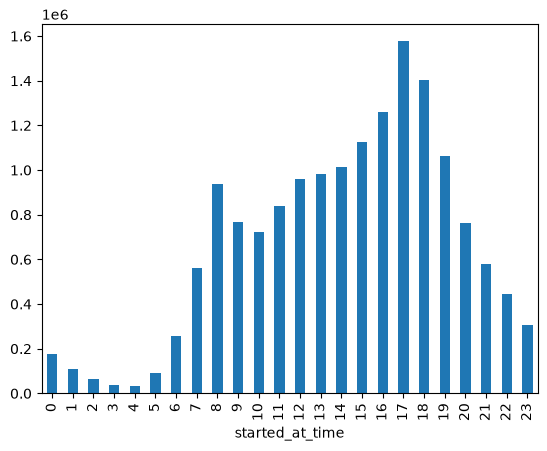

In [6]:
drd_with_weather['started_at_time'].value_counts().sort_index(ascending=True).plot(kind='bar')

- выбираю данные с 23 вечера до 8 часов утра включительно

In [7]:
night_hours = [23, 0, 1, 2, 3, 4, 5, 6, 7, 8]

night_rides = drd_with_weather[
    drd_with_weather['started_at_time'].isin(night_hours) &
    drd_with_weather['ended_at_time'].isin(night_hours)
]

- проверяю что получилось правильно

In [8]:
np.sort(night_rides['started_at_time'].unique())

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8, 23], dtype=int32)

- вывожу результат

In [9]:
night_rides

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,temp,...,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes,started_at_time,ended_at_time,year
32,docked_bike,21st St & Constitution Ave NW,31261,19th St & Constitution Ave NW,31235,2020-05-30 00:02:43.000,2020-05-30 00:13:33.000,casual,2020-05-30,24.299999,...,13.8,16.0,32.700001,4.17,0.0,rain,10.833333,0,0,2020
36,docked_bike,17th & K St NW,31213,Montello Ave & Holbrook Terr NE,31524,2020-05-31 01:15:09.000,2020-05-31 01:37:03.000,member,2020-05-31,20.400000,...,6.0,16.0,28.500000,0.00,0.0,partly-cloudy-day,21.900000,1,1,2020
48,docked_bike,4th & M St SW,31108,3rd & Tingey St SE,31634,2020-05-30 07:06:52.000,2020-05-30 07:12:49.000,member,2020-05-30,24.299999,...,13.8,16.0,32.700001,4.17,0.0,rain,5.950000,7,7,2020
58,docked_bike,Lincoln Rd & Seaton Pl NE/Harry Thomas Rec Center,31523,Eckington Pl & Q St NE,31505,2020-05-08 07:02:33.000,2020-05-08 07:24:57.000,casual,2020-05-08,14.000000,...,4.9,15.9,40.000000,20.83,0.0,rain,22.400000,7,7,2020
61,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,17th & Corcoran St NW,31214,2020-05-29 00:22:18.000,2020-05-29 00:35:00.000,member,2020-05-29,26.000000,...,22.1,15.2,30.299999,0.00,0.0,partly-cloudy-day,12.700000,0,0,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086639,electric_bike,NaN,0,NaN,0,2024-08-21 23:18:27.342,2024-08-21 23:49:14.316,member,2024-08-21,20.000000,...,8.1,16.0,23.600000,0.00,0.0,partly-cloudy-day,30.782900,23,23,2024
16086663,electric_bike,NaN,0,NaN,0,2024-08-26 23:06:25.558,2024-08-26 23:10:39.221,member,2024-08-26,25.400000,...,19.4,15.4,46.099998,8.33,0.0,rain,4.227716,23,23,2024
16086667,electric_bike,NaN,0,NaN,0,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,29.600000,...,21.6,15.9,17.100000,0.00,0.0,partly-cloudy-day,0.255800,8,8,2024
16086670,electric_bike,NaN,0,NaN,0,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,...,21.9,15.7,34.599998,12.50,0.0,rain,10.186934,2,2,2024


- добавляю столбец месяц

In [10]:
night_rides['month'] = night_rides['started_at'].dt.month

- добавляю столбец квартал

In [11]:
night_rides['quarter'] = night_rides['started_at'].dt.quarter

- делаю группировку по столбцам 'year', 'month' и делаю сумму по столбцу 'duration_in_minutes', сразу строю график

<Axes: xlabel='year,month'>

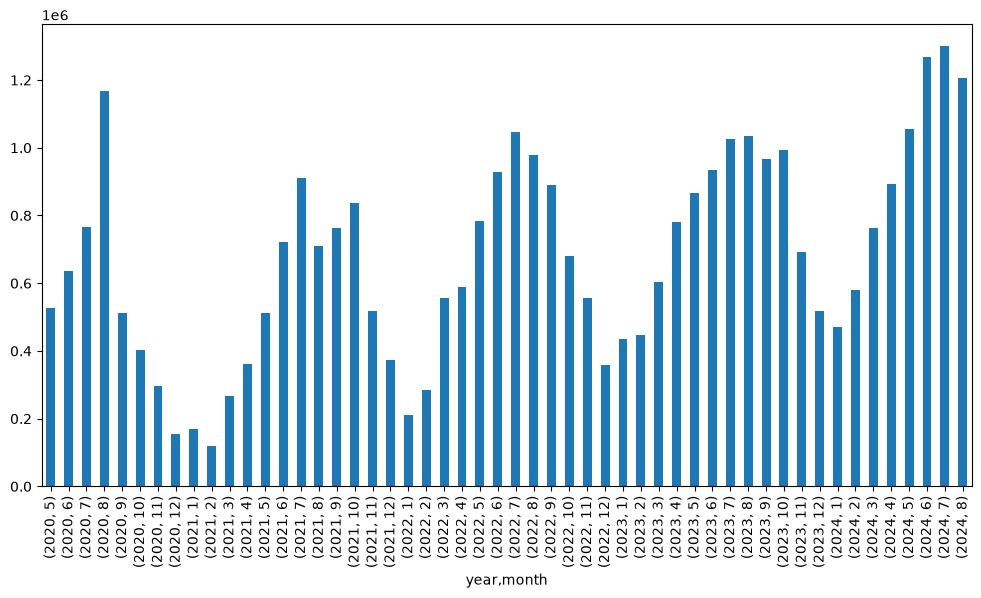

In [12]:
night_rides.groupby(['year', 'month'])['duration_in_minutes'].sum().plot(kind='bar', figsize=(12, 6))

- выбираю данные с 9 часов утра до 23 часов

In [13]:
day_rides = drd_with_weather[
    drd_with_weather['started_at_time'].between(9, 22) &
    drd_with_weather['ended_at_time'].between(9, 22)
]

- проверяю что получилось правильно

In [14]:
np.sort(day_rides['started_at_time'].unique())

array([ 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22],
      dtype=int32)

- делаю группировку по году и считаю сумму по столбцу duration_in_minutes для дневных поездок

In [15]:
ride_a_day_group = day_rides.groupby(['year'])['duration_in_minutes'].sum()
ride_a_day_group

year
2020    61535312.0
2021    57017692.0
2022    67405512.0
2023    76082256.0
2024    53777364.0
Name: duration_in_minutes, dtype: float32

- делаю группировку по году и считаю сумму по столбцу duration_in_minutes для ночных поездок

In [16]:
ride_a_night_group = night_rides.groupby(['year'])['duration_in_minutes'].sum()
ride_a_night_group

year
2020    4459351.5
2021    6259740.0
2022    7860950.5
2023    9302718.0
2024    7537062.5
Name: duration_in_minutes, dtype: float32

- считаю рост количества минут аренды 

In [17]:
ride_a_night_group.reset_index()['duration_in_minutes'].pct_change() * 100

0          NaN
1    40.373325
2    25.579500
3    18.340885
4   -18.979996
Name: duration_in_minutes, dtype: float32

In [18]:
ride_a_night_group_count = night_rides.groupby(['year'])['duration_in_minutes'].count()
ride_a_night_group_count

year
2020    180892
2021    382917
2022    513734
2023    686385
2024    601722
Name: duration_in_minutes, dtype: int64

- считаю рост количества аренды 

In [20]:
ride_a_night_group_count.reset_index()['duration_in_minutes'].pct_change() * 100

0           NaN
1    111.682661
2     34.163278
3     33.607081
4    -12.334623
Name: duration_in_minutes, dtype: float64

- сбрасываю индексы для дневных поездок

In [21]:
ride_a_day_group = ride_a_day_group.reset_index()
ride_a_day_group

,year,duration_in_minutes
0,2020,61535312.0
1,2021,57017692.0
2,2022,67405512.0
3,2023,76082256.0
4,2024,53777364.0


- добавляю столбец ride_a_night

In [22]:
ride_a_day_group['ride_a_night'] = ride_a_night_group.values

- меняю название столбцу 'duration_in_minutes' на 'ride_a_day'

In [23]:
ride_a_day_group.rename(columns={'duration_in_minutes': 'ride_a_day'}, inplace=True)

- расчитываю долю ночных поездок от дневных

In [24]:
ride_a_day_group['share_percent'] = (ride_a_day_group['ride_a_night'] / ride_a_day_group['ride_a_day']) * 100

In [25]:
ride_a_day_group

,year,ride_a_day,ride_a_night,share_percent
0,2020,61535312.0,4459351.5,7.246817
1,2021,57017692.0,6259740.0,10.978592
2,2022,67405512.0,7860950.5,11.662178
3,2023,76082256.0,9302718.0,12.227185
4,2024,53777364.0,7537062.5,14.015306


- добавляю столбец 'pct_more', который покаже во сколько раз дневные поездки больше ночных

In [26]:
ride_a_day_group['pct_more'] = (
    (ride_a_day_group['ride_a_day'] - ride_a_day_group['ride_a_night']) / ride_a_day_group['ride_a_night'] * 100
)

- вывожу результат

In [27]:
ride_a_day_group

,year,ride_a_day,ride_a_night,share_percent,pct_more
0,2020,61535312.0,4459351.5,7.246817,1279.916138
1,2021,57017692.0,6259740.0,10.978592,810.863586
2,2022,67405512.0,7860950.5,11.662178,757.472778
3,2023,76082256.0,9302718.0,12.227185,717.849731
4,2024,53777364.0,7537062.5,14.015306,613.505615


- строю график где выведу на сколько дневные поездки во сколько раз больше чем ночные

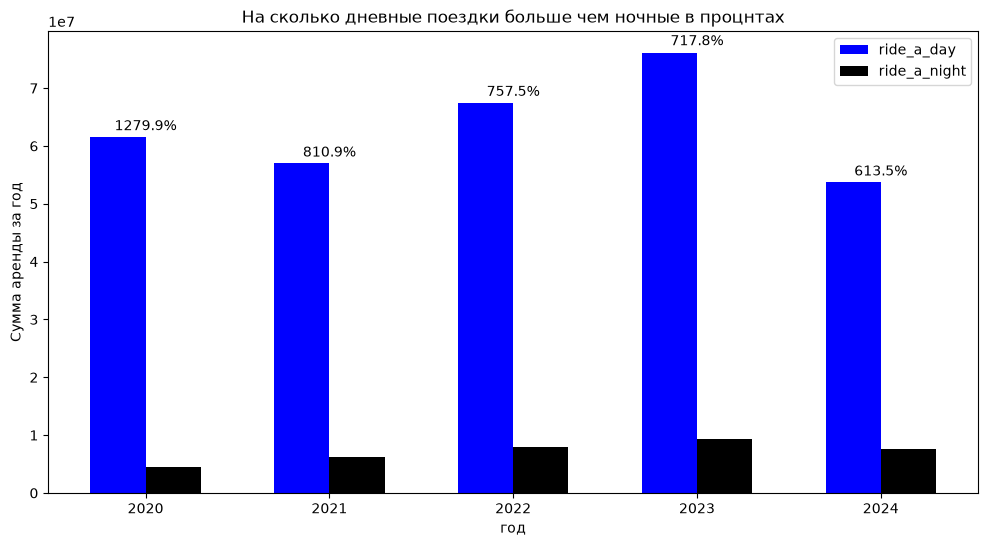

In [28]:
width = 0.3

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    ride_a_day_group['year'] - width/2,
    ride_a_day_group['ride_a_day'],
    width=width,
    label='ride_a_day',
    color='blue'
)

ax.bar(
    ride_a_day_group['year'] + width/2,
    ride_a_day_group['ride_a_night'],
    width=width,
    label='ride_a_night',
    color='black'
)

for i, pct in enumerate(ride_a_day_group['pct_more']):
    y = max(
        ride_a_day_group['ride_a_day'].iloc[i],
        ride_a_day_group['ride_a_night'].iloc[i]
    )

    ax.text(
        ride_a_day_group['year'].iloc[i],
        y * 1.01,
        f'{pct:.1f}%',
        ha='center',
        va='bottom'
    )
ax.set_xlabel('год')
ax.set_ylabel('Сумма аренды за год')
ax.set_title('На сколько дневные поездки больше чем ночные в процнтах')

ax.legend()
plt.show()

- откидываю поездки которые более 100 минут

In [29]:
night_rides_less_100 = night_rides[night_rides['duration_in_minutes'] <= 100] 

- группирую данные по столбцу rideable_type и member_casual и считаю агрегацию по столбцу change (mean, median, min, max, count)

In [30]:
ride_a_night_group = night_rides_less_100.groupby(
    ['rideable_type', 'member_casual']
)['duration_in_minutes'].agg(['mean', 'median', 'min', 'max', 'count'])

ride_a_night_group

mean     median  min         max    count
rideable_type member_casual                                                
classic_bike  casual         14.934494  11.083333  0.0  100.000000   371067
              member         10.594594   8.616667  0.0   99.966667  1071528
docked_bike   casual         22.357237  16.750000  0.0  100.000000    78035
              member         12.113302  10.000000  0.0   99.733330    91164
electric_bike casual         12.819282   9.933333  0.0   99.983330   260110
              member         11.154780   8.866667  0.0   99.983330   483886

- также вывожу график что бы посмотреть динамику по годам (данные в минутах) 2024 год еще не закончился

<Axes: xlabel='year'>

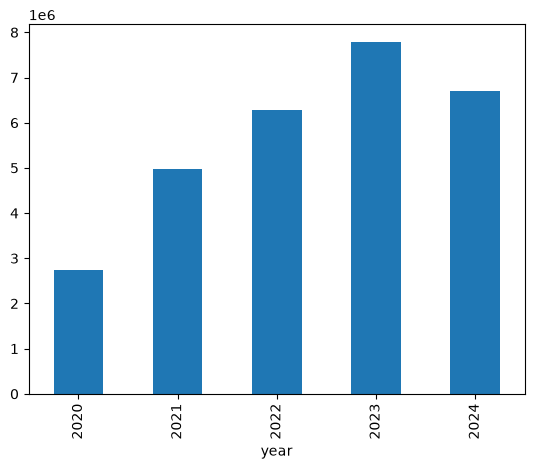

In [31]:
night_rides_less_100.groupby(['year'])['duration_in_minutes'].sum().plot(kind='bar')

- также вывожу график что бы посмотреть динамику по годам (данные в количестве поездок в год) 2024 год еще не закончился

<Axes: xlabel='year'>

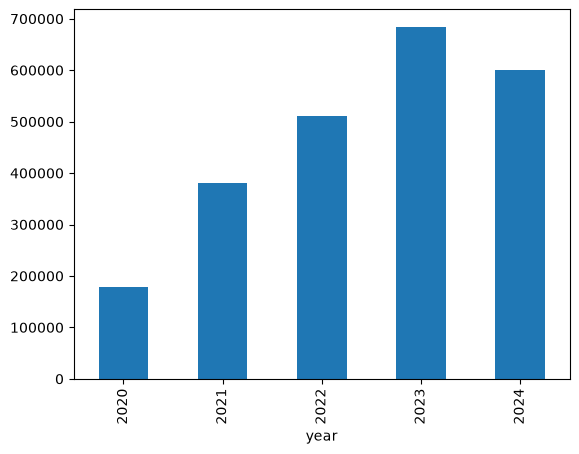

In [32]:
night_rides_less_100.groupby(['year'])['duration_in_minutes'].count().plot(kind='bar')

In [33]:
night_rides_less_100.groupby(['year'])['duration_in_minutes'].sum().pct_change() * 100

year
2020          NaN
2021    82.176628
2022    26.312756
2023    23.936451
2024   -14.084148
Name: duration_in_minutes, dtype: float32

In [34]:
night_rides_less_100.columns

Index(['rideable_type', 'start_station_name', 'start_station_id',
       'end_station_name', 'end_station_id', 'started_at', 'ended_at',
       'member_casual', 'date', 'temp', 'feelslike', 'humidity', 'dew',
       'visibility', 'windspeed', 'precipcover', 'snow', 'icon',
       'duration_in_minutes', 'started_at_time', 'ended_at_time', 'year',
       'month', 'quarter'],
      dtype='str')

In [35]:
night_rides_less_100.groupby(['year', 'month', 'start_station_id'])['duration_in_minutes'].count()

year  month  start_station_id
2020  5      31000                5
             31001                3
             31002               10
             31003               14
             31004                1
                                 ..
2024  8      32606               24
             32607               14
             32608                4
             32609               27
             33200               34
Name: duration_in_minutes, Length: 32297, dtype: int64

In [36]:
night_rides_less_100.groupby(['year'])['duration_in_minutes'].count().pct_change() * 100

year
2020           NaN
2021    112.451386
2022     34.308692
2023     33.807802
2024    -12.288368
Name: duration_in_minutes, dtype: float64

- занимаемая доля ночных поездок

In [37]:
(len(night_rides) / len(drd_with_weather)) * 100

14.71353344667623

- посмотрел в интернете сколько можно проехать на разных велосипедах за 1 минуту
    - на классик байк можно проехать 300 метров за минуту
    - на электрическом можно проехать 450 метров за минуту

- сбрасываю индексы

In [38]:
ride_a_night_group = ride_a_night_group.reset_index()
ride_a_night_group

,rideable_type,member_casual,mean,median,min,max,count
0,classic_bike,casual,14.934494,11.083333,0.0,100.000000,371067
1,classic_bike,member,10.594594,8.616667,0.0,99.966667,1071528
2,docked_bike,casual,22.357237,16.750000,0.0,100.000000,78035
3,docked_bike,member,12.113302,10.000000,0.0,99.733330,91164
4,electric_bike,casual,12.819282,9.933333,0.0,99.983330,260110
5,electric_bike,member,11.154780,8.866667,0.0,99.983330,483886


- создаю переменную dict_type_bike

In [39]:
dict_type_bike = {'classic_bike': 300, 'electric_bike': 450}

- делаю расчеты сколько можно в среднем проехать на разных велосипедах

In [40]:
ride_a_night_group['dictance_for_mean'] = ride_a_night_group['mean'] * ride_a_night_group['rideable_type'].map(dict_type_bike)

- вывожу результат

In [41]:
ride_a_night_group

,rideable_type,member_casual,mean,median,min,max,count,dictance_for_mean
0,classic_bike,casual,14.934494,11.083333,0.0,100.000000,371067,4480.348206
1,classic_bike,member,10.594594,8.616667,0.0,99.966667,1071528,3178.378201
2,docked_bike,casual,22.357237,16.750000,0.0,100.000000,78035,NaN
3,docked_bike,member,12.113302,10.000000,0.0,99.733330,91164,NaN
4,electric_bike,casual,12.819282,9.933333,0.0,99.983330,260110,5768.676710
5,electric_bike,member,11.154780,8.866667,0.0,99.983330,483886,5019.651175


- делаю расчеты сколько можно по медиане проехать на разных велосипедах

In [42]:
ride_a_night_group['dictance_for_median'] = ride_a_night_group['median'] * ride_a_night_group['rideable_type'].map(dict_type_bike)

- вывожу результат

In [43]:
ride_a_night_group

,rideable_type,member_casual,mean,median,min,max,count,dictance_for_mean,dictance_for_median
0,classic_bike,casual,14.934494,11.083333,0.0,100.000000,371067,4480.348206,3324.999905
1,classic_bike,member,10.594594,8.616667,0.0,99.966667,1071528,3178.378201,2585.000038
2,docked_bike,casual,22.357237,16.750000,0.0,100.000000,78035,NaN,NaN
3,docked_bike,member,12.113302,10.000000,0.0,99.733330,91164,NaN,NaN
4,electric_bike,casual,12.819282,9.933333,0.0,99.983330,260110,5768.676710,4470.000029
5,electric_bike,member,11.154780,8.866667,0.0,99.983330,483886,5019.651175,3990.000057


### Вывод по гипотезе 11 - На сколько можно увеличить количество аренды в такие часы как с 23 до 8 позиционируя их как ночной тариф

- От года к году в среднем увеличивается количество поездок на 33 % (2024 год еще не закончен)
- От года к году в среднем увеличивается суммарное количество минут аренды на 27 % (2024 год еще не закончен)
- Буду наблюдать как закончится 2024 год и дальше можно будет смотреть что можно будет сделать
- Доля занимаемых ночных поездок 14.71 %
- Есть целесообразность развития ночных поездок потому что людей ночью берет в аренду меньше чем днем
- Цель достигнуть в количестве 1 миллиона аредны в велосипедов ночных поездок 2025
- Также можно увеличить на 25-30% в 2024 году количество аренды велосипедов по сравнению с 2023 годом
- Нельзя достигнуть уровня дневных поездок в 2024, который больше ночных на 613.5% (или в 6.13 раза больше)